In [1]:
#Installing libraries
!pip install pandas numpy matplotlib seaborn scipy
!pip install statsmodels scikit-learn patsy openpyxl

In [2]:
#Import the library files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from scipy.stats import nbinom
from patsy import dmatrix

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully")

All libraries imported successfully


In [3]:
#Import and prepare excel data
file_path = r"C:\Users\HP\Desktop\STAT 3103\Dengue data.xlsx"
data = pd.read_excel(file_path)

print(data.head())
print(data.shape)
print(data.info())

   Year  Months Months.1  Cases  Deaths    T2M  T2M_MIN  T2M_MAX   RH2M  \
0  2000       1      Jan      0       0  18.45     8.02    28.19  62.06   
1  2000       2      Feb      0       0  20.55    10.82    29.90  52.38   
2  2000       3      Mar      0       0  25.77    14.50    36.07  55.94   
3  2000       4      Apr      0       0  29.44    22.97    39.67  67.94   
4  2000       5      May      0       0  28.51    22.91    37.55  81.62   

   PRECTOTCORR  ...    EA   SSS   PG     FR    AGR     AL  Precipitation(mm)  \
0         0.34  ...  32.0  18.0  2.0  14.75  72.21  64.15            2332.39   
1         0.77  ...  32.0  18.0  2.0  14.75  72.21  64.15            2332.39   
2         2.49  ...  32.0  18.0  2.0  14.75  72.21  64.15            2332.39   
3         5.17  ...  32.0  18.0  2.0  14.75  72.21  64.15            2332.39   
4        13.24  ...  32.0  18.0  2.0  14.75  72.21  64.15            2332.39   

   WC(tons)         AP   CHE  
0  11085.51  1331369.0  2.07  
1  110

In [5]:
#Fitting column name 
data.columns = data.columns.str.strip()

required = [
    'Cases', 'Year', 'Months',
    'T2M', 'RH2M', 'PRECTOTCORR', 'Pd'
]

missing = set(required) - set(data.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

In [6]:
#Data variable 
data['Date'] = pd.to_datetime(
    dict(
        year=data['Year'],
        month=data['Months'],
        day=1
    ),
    errors='coerce'
)

data = data.sort_values('Date').reset_index(drop=True)

print(data[['Year', 'Months', 'Date']].head())

   Year  Months       Date
0  2000       1 2000-01-01
1  2000       2 2000-02-01
2  2000       3 2000-03-01
3  2000       4 2000-04-01
4  2000       5 2000-05-01


In [7]:
#Checking Data Quality
print("Missing values:")
print(data[required].isnull().sum())

print("Duplicate dates:", data['Date'].duplicated().sum())

print("Negative cases:", (data['Cases'] < 0).sum())

print("Non-integer cases:",
      (~np.isclose(data['Cases'].dropna() % 1, 0)).sum())

print("Zero cases:", (data['Cases'] == 0).sum())

print("Percentage of zeros:",
      (data['Cases'] == 0).mean() * 100)

print("Mean:", data['Cases'].mean())

print("Variance:", data['Cases'].var())

Missing values:
Cases          0
Year           0
Months         0
T2M            0
RH2M           0
PRECTOTCORR    0
Pd             0
dtype: int64
Duplicate dates: 0
Negative cases: 0
Non-integer cases: 0
Zero cases: 84
Percentage of zeros: 31.818181818181817
Mean: 687.9621212121212
Variance: 13359098.911107272


In [8]:
data = data.dropna(subset=required + ['Date']).copy()

data['Cases'] = data['Cases'].astype(int)

if data['Date'].duplicated().any():
    raise ValueError("Resolve duplicate months before modeling.")

if (data['Cases'] < 0).any():
    raise ValueError("Negative count detected.")

data['trend'] = (
    (data['Date'] - data['Date'].min()).dt.days / 365.25
)

data['month_cat'] = data['Date'].dt.month.astype(str)

data = data.reset_index(drop=True)

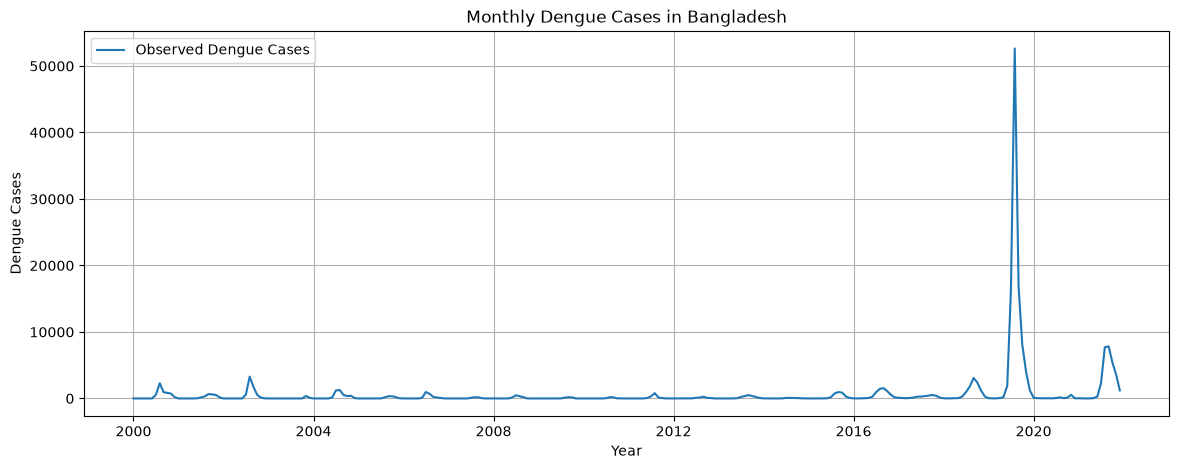

In [9]:
#Explanatory Data Analysis
plt.figure(figsize=(14,5))

plt.plot(
    data['Date'],
    data['Cases'],
    label='Observed Dengue Cases'
)

plt.xlabel('Year')
plt.ylabel('Dengue Cases')
plt.title('Monthly Dengue Cases in Bangladesh')
plt.legend()
plt.grid()
plt.show()

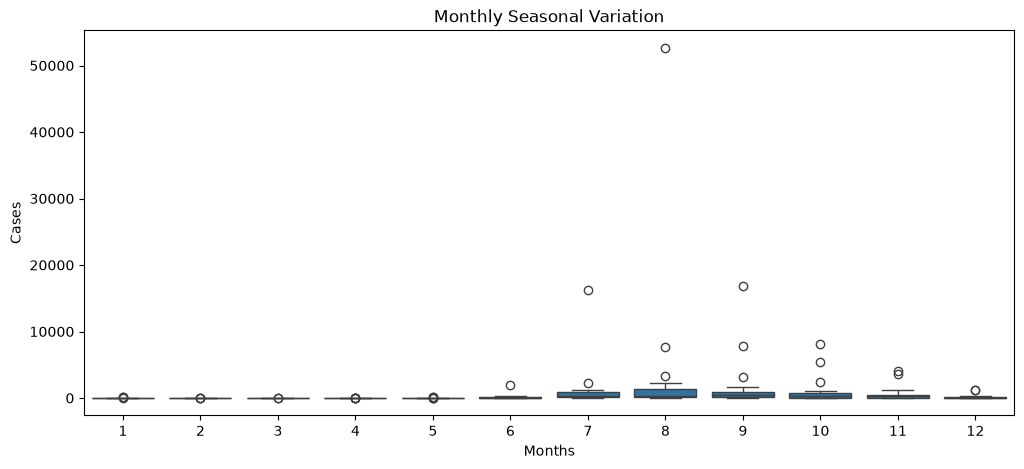

In [13]:
#Seasonal Variation
plt.figure(figsize=(12,5))

sns.boxplot(
    data=data,
    x='Months',
    y='Cases'
)

plt.title('Monthly Seasonal Variation')
plt.show()

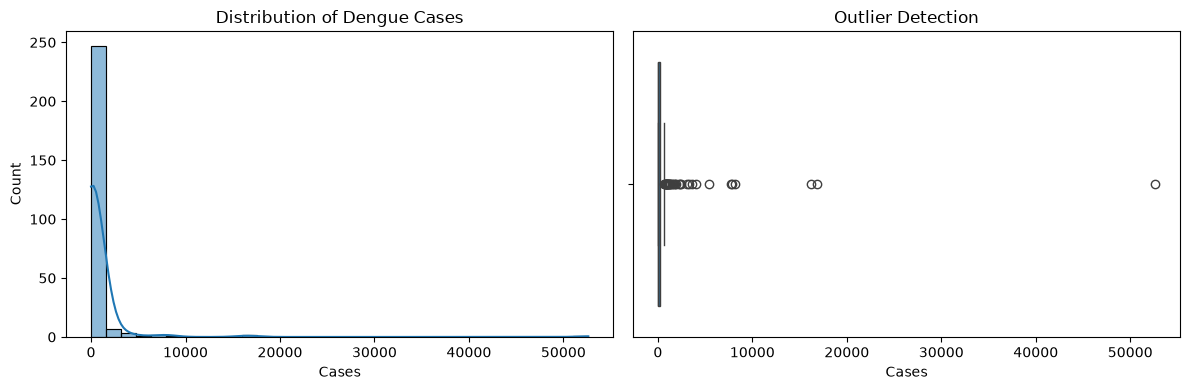

In [14]:
#Distribution of Dengue Cases
fig, ax = plt.subplots(1, 2, figsize=(12,4))

sns.histplot(data['Cases'], kde=True, ax=ax[0])

sns.boxplot(x=data['Cases'], ax=ax[1])

ax[0].set_title('Distribution of Dengue Cases')
ax[1].set_title('Outlier Detection')

plt.tight_layout()
plt.show()

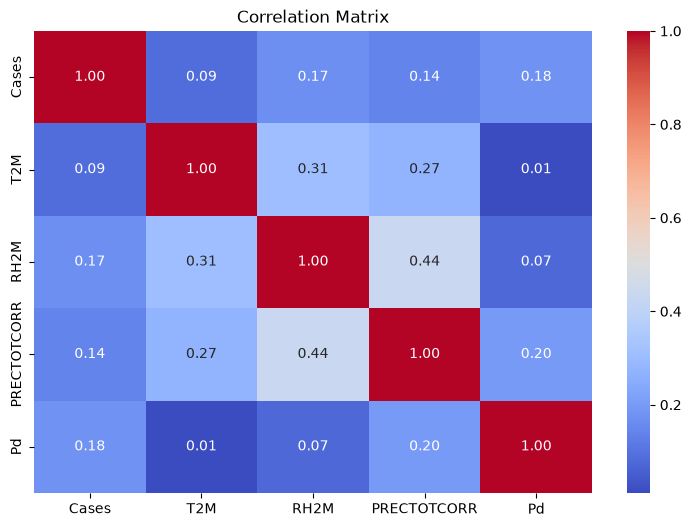

In [15]:
#Correlation Anlysis
variables = [
    'Cases', 'T2M',
    'RH2M', 'PRECTOTCORR', 'Pd'
]

plt.figure(figsize=(9,6))

sns.heatmap(
    data[variables].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [16]:
#Checking The Overdispersion 
mean_cases = data['Cases'].mean()
variance_cases = data['Cases'].var()

print("Mean:", mean_cases)
print("Variance:", variance_cases)

print("Variance / Mean:",
      variance_cases / mean_cases)

Mean: 687.9621212121212
Variance: 13359098.911107272
Variance / Mean: 19418.364033720143


In [17]:
#Zero Analysis 
observed_zeros = (data['Cases'] == 0).sum()
total = len(data)

print("Total observations:", total)
print("Observed zeros:", observed_zeros)
print("Zero percentage:", observed_zeros/total*100)

Total observations: 264
Observed zeros: 84
Zero percentage: 31.818181818181817


In [18]:
#Multicolinearity Checking 
X_vif = data[
    ['T2M', 'RH2M', 'PRECTOTCORR', 'Pd']
].copy()

X_vif = sm.add_constant(X_vif)

vif_table = pd.DataFrame()

vif_table['Variable'] = X_vif.columns

vif_table['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_table)

      Variable         VIF
0        const  245.777290
1          T2M    1.134901
2         RH2M    1.294813
3  PRECTOTCORR    1.316452
4           Pd    1.043972


In [19]:
#Train Test
split = int(len(data) * 0.80)

train = data.iloc[:split].copy()
test = data.iloc[split:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:",
      train['Date'].min(), "to", train['Date'].max())

print("Testing period:",
      test['Date'].min(), "to", test['Date'].max())

Training observations: 211
Testing observations: 53
Training period: 2000-01-01 00:00:00 to 2017-07-01 00:00:00
Testing period: 2017-08-01 00:00:00 to 2021-12-01 00:00:00


In [20]:
#Fitting Poisson Model 
formula = """
Cases ~ trend + C(month_cat)
+ T2M + RH2M + PRECTOTCORR + Pd
"""

poisson_model = smf.glm(
    formula=formula,
    data=train,
    family=sm.families.Poisson()
).fit()

print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Cases   No. Observations:                  211
Model:                            GLM   Df Residuals:                      194
Model Family:                 Poisson   Df Model:                           16
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -17482.
Date:                Wed, 18 Nov 2026   Deviance:                       34165.
Time:                        02:09:46   Pearson chi2:                 4.05e+04
No. Iterations:                     8   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             92.6367      1

In [21]:
#Fitting Negative Binomial
nb_model = smf.negativebinomial(
    formula=formula,
    data=train
).fit(disp=0, maxiter=500)

print(nb_model.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:                  Cases   No. Observations:                  211
Model:               NegativeBinomial   Df Residuals:                      194
Method:                           MLE   Df Model:                           16
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                 0.08904
Time:                        02:10:40   Log-Likelihood:                -882.59
converged:                       True   LL-Null:                       -968.85
Covariance Type:            nonrobust   LLR p-value:                 2.625e-28
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            137.1410     30.167      4.546      0.000      78.016     196.266
C(month_cat)[T.10]    -0.1079      2.637     -0.041      0.967      -5.276       5.060
C(month_cat)[T.11]  

In [22]:
#Fitting Zero Inflated Poisson
y_train = train['Cases']

X_train = dmatrix(
    "1 + trend + C(month_cat) + T2M + RH2M + PRECTOTCORR + Pd",
    train,
    return_type='dataframe'
)

Z_train = dmatrix(
    "1 + trend",
    train,
    return_type='dataframe'
)

from statsmodels.discrete.count_model import (
    ZeroInflatedPoisson,
    ZeroInflatedNegativeBinomialP
)

zip_model = ZeroInflatedPoisson(
    endog=y_train,
    exog=X_train,
    exog_infl=Z_train,
    inflation='logit'
).fit(
    method='bfgs',
    maxiter=500,
    disp=0
)

print(zip_model.summary())

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:                   Cases   No. Observations:                  211
Model:             ZeroInflatedPoisson   Df Residuals:                      194
Method:                            MLE   Df Model:                           16
Date:                 Wed, 18 Nov 2026   Pseudo R-squ.:                -0.05487
Time:                         02:11:27   Log-Likelihood:                -33593.
converged:                       False   LL-Null:                       -31845.
Covariance Type:             nonrobust   LLR p-value:                     1.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
inflate_Intercept      0.1000      0.290      0.344      0.731      -0.469       0.669
inflate_trend          0.1000      0.032      3.136      0.002       0.037       0.163
Intercept   

In [23]:
#Fitting Zero Inflated Negative Binomial
zinb_model = ZeroInflatedNegativeBinomialP(
    endog=y_train,
    exog=X_train,
    exog_infl=Z_train,
    inflation='logit',
    p=2
).fit(
    method='bfgs',
    maxiter=500,
    disp=0
)

print(zinb_model.summary())

                     ZeroInflatedNegativeBinomialP Regression Results                    
Dep. Variable:                             Cases   No. Observations:                  211
Model:             ZeroInflatedNegativeBinomialP   Df Residuals:                      194
Method:                                      MLE   Df Model:                           16
Date:                           Wed, 18 Nov 2026   Pseudo R-squ.:                     nan
Time:                                   02:12:05   Log-Likelihood:                    nan
converged:                                 False   LL-Null:                       -961.21
Covariance Type:                       nonrobust   LLR p-value:                       nan
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
inflate_Intercept     -4.5965        nan        nan        nan         nan         nan
inflate_trend      

In [24]:
#Compare The 3 Models AIC,BIC,Log likelihood
models = {
    'Poisson': poisson_model,
    'Negative Binomial': nb_model,
    'ZIP': zip_model,
    'ZINB': zinb_model
}

comparison = []

for name, model in models.items():

    comparison.append({
        'Model': name,
        'AIC': model.aic,
        'BIC': model.bic,
        'LogLikelihood': model.llf,
        'Converged': getattr(
            model, 'converged', True
        )
    })

comparison_df = pd.DataFrame(comparison)

print(
    comparison_df.sort_values('AIC')
)

               Model           AIC           BIC  LogLikelihood  Converged
1  Negative Binomial   1801.170084   1861.503530    -882.585042       True
0            Poisson  34998.710685  33127.000385  -17482.355343       True
2                ZIP  67223.392986  67287.078291  -33592.696493      False
3               ZINB           NaN           NaN            NaN      False


In [25]:
#Forecasting Perfomance
X_test = dmatrix(
    "1 + trend + C(month_cat) + T2M + RH2M + PRECTOTCORR + Pd",
    test,
    return_type='dataframe'
)

Z_test = dmatrix(
    "1 + trend",
    test,
    return_type='dataframe'
)

predictions = {}

predictions['Poisson'] = poisson_model.predict(test)

predictions['Negative Binomial'] = nb_model.predict(test)

predictions['ZIP'] = zip_model.predict(
    exog=X_test,
    exog_infl=Z_test
)

predictions['ZINB'] = zinb_model.predict(
    exog=X_test,
    exog_infl=Z_test
)

In [39]:
results = []

for name, pred in predictions.items():
    try:
        
        pred_arr = np.asarray(pred, dtype=float).ravel()
        y_true_arr = np.asarray(y_true, dtype=float).ravel()
        
        
        pred_arr = np.nan_to_num(pred_arr, nan=0.0, posinf=1e10, neginf=0.0)
        
        
        pred_arr = np.maximum(pred_arr, 0)
        y_true_arr = np.maximum(y_true_arr, 0)
        
       
        pred_arr = np.clip(pred_arr, 0, 1e12)
        
        y_true_int = y_true_arr.astype(int)

        results.append({
            'Model': name,
            'MAE': mean_absolute_error(y_true_arr, pred_arr),
            'RMSE': np.sqrt(mean_squared_error(y_true_arr, pred_arr)),
            'Poisson Deviance': mean_poisson_deviance(y_true_int, pred_arr)
        })
    except Exception as e:
        print(f"Error in model {name}: {e}")

if results:
    performance = pd.DataFrame(results)
    print(performance.sort_values('RMSE'))
else:
    print("কোনো ফলাফল যোগ করা সম্ভব হয়নি।")

               Model           MAE          RMSE  Poisson Deviance
1  Negative Binomial  2.792839e+03  7.540002e+03      6.102498e+03
0            Poisson  2.502126e+03  7.983509e+03      1.111203e+04
2                ZIP  2.672031e+03  8.229049e+03      2.738766e+04
3               ZINB  9.999997e+09  9.999997e+09      1.999992e+10


In [40]:
#Over Dispersion Diagonostic 
pearson_chi2 = sum(poisson_model.resid_pearson**2)

dispersion = (
    pearson_chi2 / poisson_model.df_resid
)

print("Pearson Chi-square:", pearson_chi2)
print("Residual df:", poisson_model.df_resid)
print("Dispersion:", dispersion)

Pearson Chi-square: 40494.27460795452
Residual df: 194
Dispersion: 208.7333742678068


In [41]:
#Expected vs Observed Zero
mu_pois = poisson_model.predict(train)

observed_zero = (train['Cases'] == 0).sum()

expected_zero_pois = np.exp(-mu_pois).sum()

alpha = nb_model.params['alpha']

mu_nb = nb_model.predict(train)

size = 1 / alpha

prob = size / (size + mu_nb)

expected_zero_nb = nbinom.pmf(
    0,
    size,
    prob
).sum()

print("Observed Zero:", observed_zero)

print("Expected Poisson Zero:", expected_zero_pois)

print("Expected NB Zero:", expected_zero_nb)

Observed Zero: 84
Expected Poisson Zero: 6.188253345011904
Expected NB Zero: 67.77699484571329


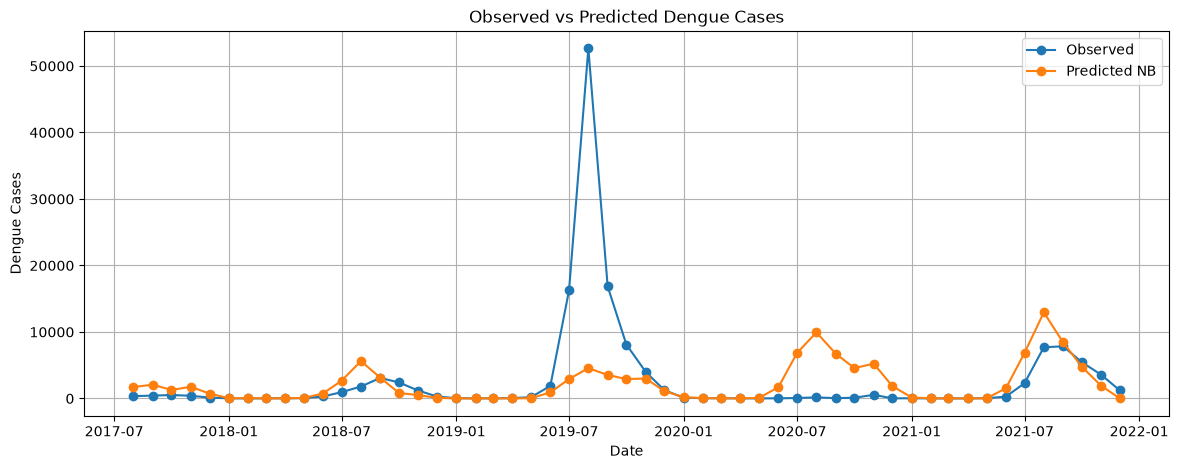

In [42]:
#Observed vs Predicted Plot 
plt.figure(figsize=(14,5))

plt.plot(
    test['Date'],
    y_true,
    label='Observed',
    marker='o'
)

plt.plot(
    test['Date'],
    predictions['Negative Binomial'],
    label='Predicted NB',
    marker='o'
)

plt.xlabel('Date')
plt.ylabel('Dengue Cases')

plt.title('Observed vs Predicted Dengue Cases')

plt.legend()
plt.grid()

plt.show()

In [43]:
#Coefficient Interpretation 
params = nb_model.params
conf = nb_model.conf_int()

irr_table = pd.DataFrame({
    'Coefficient': params,
    'IRR': np.exp(params),
    'Lower IRR': np.exp(conf[0]),
    'Upper IRR': np.exp(conf[1]),
    'P-value': nb_model.pvalues
})

print(irr_table)

                    Coefficient           IRR     Lower IRR     Upper IRR  \
Intercept            137.140971  3.627161e+59  7.617158e+33  1.727193e+85   
C(month_cat)[T.10]    -0.107914  8.977045e-01  5.114568e-03  1.575643e+02   
C(month_cat)[T.11]     0.506449  1.659388e+00  7.140449e-02  3.856297e+01   
C(month_cat)[T.12]    -0.368320  6.918959e-01  1.084159e-01  4.415588e+00   
C(month_cat)[T.2]      0.689305  1.992331e+00  2.830091e-01  1.402564e+01   
C(month_cat)[T.3]     -0.131562  8.767251e-01  1.551847e-02  4.953111e+01   
C(month_cat)[T.4]     -2.153736  1.160498e-01  3.458023e-04  3.894584e+01   
C(month_cat)[T.5]     -2.457168  8.567723e-02  1.613299e-04  4.550049e+01   
C(month_cat)[T.6]     -0.961830  3.821928e-01  6.096901e-04  2.395829e+02   
C(month_cat)[T.7]      0.214055  1.238691e+00  1.932878e-03  7.938189e+02   
C(month_cat)[T.8]      0.402499  1.495558e+00  2.554767e-03  8.754976e+02   
C(month_cat)[T.9]     -0.017873  9.822860e-01  2.090275e-03  4.616071e+02   

In [45]:
final_nb = smf.negativebinomial(
    formula=formula,
    data=data
).fit(disp=0, maxiter=500)

print(final_nb.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:                  Cases   No. Observations:                  264
Model:               NegativeBinomial   Df Residuals:                      247
Method:                           MLE   Df Model:                           16
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.1058
Time:                        02:59:04   Log-Likelihood:                -1277.2
converged:                      False   LL-Null:                       -1428.3
Covariance Type:            nonrobust   LLR p-value:                 8.362e-55
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            142.4215     24.640      5.780      0.000      94.129     190.714
C(month_cat)[T.10]     1.5068      2.010      0.750      0.453      -2.432       5.446
C(month_cat)[T.11]  